# Chapter 4: Causal Inference, Foundations

**Aventum Round 1 prep · STRATEGY.md §5.3** · Time needed: about 2 hours. **This is the gap the JD names most clearly, so give it the most time.**

### Syllabus
| No. | Topic | Interview use |
|---|---|---|
| 4.1 | Potential outcomes, ATE / CATE, the fundamental problem | "Did the AI tool *cause* the improvement?" |
| 4.2 | Confounding and the adjustment formula | "Why can't you just compare users vs non-users?" |
| 4.3 | Estimators by hand: regression adjustment, IPW, AIPW (doubly robust) | "How would you estimate the effect without an A/B test?" |
| 4.4 | DAGs, the backdoor criterion, colliders and mediators | "What would you control for?" |
| 4.5 | Heterogeneous effects: S-learner and T-learner (uplift) | "For which risks does it help most?" |
| 4.6 | Difference-in-differences (+ RDD, IV, synthetic control) | "We rolled it out to half the teams. Did it work?" |

**Running story for the whole chapter:** Aventum gives underwriters an **AI triage tool**. Outcome $Y$ = **hours to quote**. Treatment $T = 1$ if the tool was used on the submission. **True effect (known only because we simulate): the tool saves 2 hours on average.**

## 0. Setup

In [1]:
import numpy as np                  # linear algebra
import pandas as pd                 # data processing
import matplotlib.pyplot as plt     # plots
import statsmodels.formula.api as smf
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import GradientBoostingRegressor

np.random.seed(42)
print("Ready")

Ready


---
## 4.1 Potential Outcomes

### Definitions
For each submission $i$ imagine **two** outcomes:
- $Y_i(1)$: hours to quote **if the tool is used**
- $Y_i(0)$: hours to quote **if it is not**

**Individual treatment effect:** $\tau_i = Y_i(1) - Y_i(0)$

$$\boxed{\text{ATE} = E[Y(1) - Y(0)]} \qquad \boxed{\text{CATE}(x) = E[Y(1) - Y(0) \mid X = x]}$$

**The fundamental problem of causal inference:** we only ever see **one** of the two for each unit. The other is the **counterfactual**. So causal inference is a **missing-data problem**.

### Solved Example 4.1 (the god's-eye table)
**Q.** Four submissions. We (magically) know both potential outcomes. Easy risks tend to get the tool.

| Sub | Complexity | T | Y(0) | Y(1) | τ |
|---|---|---|---|---|---|
| 1 | easy | 1 | 6 | 4 | −2 |
| 2 | easy | 1 | 6 | 4 | −2 |
| 3 | hard | 0 | 12 | 10 | −2 |
| 4 | hard | 0 | 12 | 8 | −4 |

Find (a) the true ATE and (b) the naive "users vs non-users" difference.

**Solution.**
(a) ATE = (−2 − 2 − 2 − 4) / 4 = **−2.5 hours**

(b) We only **observe** $Y(1)$ for subs 1 and 2 (4, 4) and $Y(0)$ for subs 3 and 4 (12, 12).
Naive = mean(4, 4) − mean(12, 12) = 4 − 12 = **−8 hours**

**Ans.** The naive comparison claims the tool saves 8 hours. It truly saves 2.5. The other 5.5 hours is **confounding**: the tool was used on easy risks, which are quick anyway.

> **This is the whole point of the chapter.** "Users of the tool were 8 hours faster" is a true statement and a wrong conclusion.

---
## 4.2 Confounding and the Adjustment Formula

### Theory
A **confounder** $X$ causes both the treatment and the outcome (complexity → tool use, complexity → hours). If we compare like with like (within each level of $X$), the confounding disappears.

### Assumptions (learn all three, viva favourite)
1. **Unconfoundedness (ignorability):** given $X$, treatment is as good as random: $(Y(0), Y(1)) \perp T \mid X$. *No hidden confounders.*
2. **Positivity / overlap:** $0 < P(T=1 \mid X=x) < 1$ for every $x$. *Every kind of risk could get either treatment.*
3. **SUTVA:** one unit's treatment doesn't affect another's outcome (no interference), and there's only one version of the treatment.

### The adjustment formula
$$\boxed{\text{ATE} = \sum_x P(X=x)\,\Big(E[Y \mid T=1, X=x] - E[Y \mid T=0, X=x]\Big)}$$

### Solved Example 4.2
**Q.** 60% of submissions are easy and 40% hard. 80% of easy risks get the tool, 20% of hard ones do. Average hours:

| | Tool (T=1) | No tool (T=0) |
|---|---|---|
| Easy | 4 | 6 |
| Hard | 9 | 12 |

Find the naive difference and the adjusted ATE.

**Solution.**
*Adjusted:* Easy effect = 4 − 6 = −2. Hard effect = 9 − 12 = −3.
ATE = 0.6(−2) + 0.4(−3) = −1.2 − 1.2 = **−2.4 hours**

*Naive:*
- Treated mean = $\frac{0.6(0.8)(4) + 0.4(0.2)(9)}{0.6(0.8) + 0.4(0.2)} = \frac{1.92 + 0.72}{0.56} = 4.714$
- Control mean = $\frac{0.6(0.2)(6) + 0.4(0.8)(12)}{0.6(0.2) + 0.4(0.8)} = \frac{0.72 + 3.84}{0.44} = 10.364$
- Naive = 4.714 − 10.364 = **−5.65 hours**

**Ans.** Naive −5.65, adjusted −2.4. The treated group is mostly easy risks, so the naive comparison credits the tool with the easiness.

In [2]:
P_x  = {"easy": 0.6, "hard": 0.4}
P_t  = {"easy": 0.8, "hard": 0.2}
mean = {("easy", 1): 4, ("easy", 0): 6, ("hard", 1): 9, ("hard", 0): 12}

ate = sum(P_x[x] * (mean[(x, 1)] - mean[(x, 0)]) for x in P_x)
treated = sum(P_x[x] * P_t[x] * mean[(x, 1)] for x in P_x) / sum(P_x[x] * P_t[x] for x in P_x)
control = sum(P_x[x] * (1 - P_t[x]) * mean[(x, 0)] for x in P_x) / sum(P_x[x] * (1 - P_t[x]) for x in P_x)
print(f"adjusted ATE = {ate:.3f}   naive = {treated - control:.3f}")

adjusted ATE = -2.400   naive = -5.649


---
## 4.3 Estimators (with continuous confounders)

With continuous $X$ you can't make a table per stratum, so you **model** it. There are three families:

**(1) Regression adjustment / g-computation:** fit $\hat\mu_t(x) = E[Y \mid T=t, X=x]$, then
$$\widehat{\text{ATE}} = \frac1n \sum_i \big(\hat\mu_1(x_i) - \hat\mu_0(x_i)\big)$$

**(2) Inverse propensity weighting (IPW):** fit the **propensity score** $e(x) = P(T=1 \mid X=x)$, then
$$\boxed{\widehat{\text{ATE}}_{IPW} = \frac1n \sum_i \left(\frac{T_i Y_i}{e(x_i)} - \frac{(1-T_i) Y_i}{1 - e(x_i)}\right)}$$
*Intuition:* a treated **hard** risk is rare (e = 0.2), so it gets weight 1/0.2 = 5 and stands in for the 4 similar hard risks that weren't treated. Weighting rebuilds a population where treatment looks random.

**(3) Doubly robust (AIPW):** combine both:
$$\boxed{\widehat{\text{ATE}}_{DR} = \frac1n \sum_i \left[\hat\mu_1(x_i) - \hat\mu_0(x_i) + \frac{T_i (Y_i - \hat\mu_1(x_i))}{e(x_i)} - \frac{(1-T_i)(Y_i - \hat\mu_0(x_i))}{1-e(x_i)}\right]}$$
*Why "doubly robust":* it's consistent if **either** the outcome model **or** the propensity model is correct. The second part is an IPW-weighted correction of the outcome model's errors: if the outcome model is perfect, the residuals average to 0.

**Double ML** (EconML `LinearDML`, Notebook 05) goes further: it uses flexible ML models for both nuisance functions, with **cross-fitting** (each model is fitted on one fold and predicts on another) to avoid overfitting bias.

#### Program 4.1: simulate the triage-tool data (we know the truth)

In [3]:
rng = np.random.default_rng(7)
n = 8000
complexity = rng.normal(0, 1, n)
experience = rng.normal(0, 1, n)
e_true = 1 / (1 + np.exp(-(-1.2 * complexity + 0.5 * experience)))   # tool used on easy risks
T = (rng.random(n) < e_true).astype(int)
tau = -2.0 - 1.0 * complexity             # heterogeneous: bigger saving on complex risks
Y0 = 10 + 3 * complexity - 1.0 * experience + rng.normal(0, 2, n)
Y1 = Y0 + tau
Y = np.where(T == 1, Y1, Y0)              # we only observe one potential outcome

df = pd.DataFrame(dict(complexity=complexity, experience=experience, T=T, Y=Y))
print("TRUE ATE (we only know this because we simulated it):", round(tau.mean(), 3))
df.head()

TRUE ATE (we only know this because we simulated it): -1.981


,complexity,experience,T,Y
0,0.001230,-0.763667,0,9.396901
1,0.298746,1.331525,0,10.437704
2,-0.274138,-1.113024,0,8.931740
3,-0.890592,-0.037656,1,8.963163
4,-0.454671,-0.642366,1,9.128642


In [4]:
X = df[["complexity", "experience"]].values
naive = df.loc[df["T"] == 1, "Y"].mean() - df.loc[df["T"] == 0, "Y"].mean()

# (1) regression adjustment: one outcome model per arm (T-learner style g-computation)
mu1 = LinearRegression().fit(X[T == 1], Y[T == 1]).predict(X)
mu0 = LinearRegression().fit(X[T == 0], Y[T == 0]).predict(X)
reg_adj = np.mean(mu1 - mu0)

# (2) IPW
e_hat = LogisticRegression().fit(X, T).predict_proba(X)[:, 1]
ipw = np.mean(T * Y / e_hat - (1 - T) * Y / (1 - e_hat))

# (3) AIPW / doubly robust
aipw = np.mean(mu1 - mu0 + T * (Y - mu1) / e_hat - (1 - T) * (Y - mu0) / (1 - e_hat))

pd.DataFrame({"estimate (hours)": [tau.mean(), naive, reg_adj, ipw, aipw]},
             index=["TRUE ATE", "naive difference", "regression adjustment", "IPW", "AIPW (doubly robust)"]).round(3)

,estimate (hours)
TRUE ATE,-1.981
naive difference,-4.541
regression adjustment,-2.028
IPW,-2.054
AIPW (doubly robust),-1.998


#### Explanation
- **Naive** is far too optimistic, because the tool's users had easier risks: exactly Solved Example 4.1 at scale.
- All three adjusted estimators land near the true −2, **because we included every confounder** (complexity and experience). In real data, that assumption is the whole game, and it can't be tested from data alone. That's why DoWhy has **refuters** (Notebook 05).

#### Program 4.2: check overlap (positivity) before trusting IPW

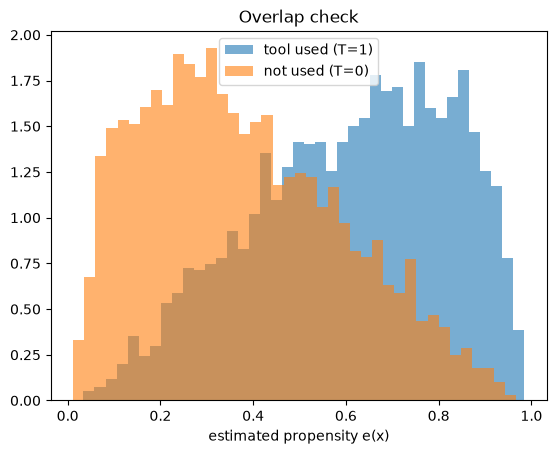

min / max propensity: 0.012 0.984


In [5]:
plt.hist(e_hat[T == 1], bins=40, alpha=0.6, density=True, label="tool used (T=1)")
plt.hist(e_hat[T == 0], bins=40, alpha=0.6, density=True, label="not used (T=0)")
plt.xlabel("estimated propensity e(x)"); plt.legend(); plt.title("Overlap check"); plt.show()
print("min / max propensity:", e_hat.min().round(3), e_hat.max().round(3))

> **Common mistake (examiner's favourite):** propensities near 0 or 1 give huge weights ($1/0.01 = 100$), so one submission dominates the estimate. Always **plot the overlap**. Fixes: trim units with $e < 0.05$ or $e > 0.95$ (this changes the population you're estimating for, so say so), use stabilised weights, or prefer AIPW.

#### Program 4.3: what if we miss a confounder?

In [6]:
Xc = df[["complexity"]].values                    # we forgot underwriter experience
mu1c = LinearRegression().fit(Xc[T == 1], Y[T == 1]).predict(Xc)
mu0c = LinearRegression().fit(Xc[T == 0], Y[T == 0]).predict(Xc)
ec = LogisticRegression().fit(Xc, T).predict_proba(Xc)[:, 1]
aipw_c = np.mean(mu1c - mu0c + T * (Y - mu1c) / ec - (1 - T) * (Y - mu0c) / (1 - ec))
print(f"AIPW with both confounders : {aipw:.3f}")
print(f"AIPW missing 'experience'  : {aipw_c:.3f}   (true {tau.mean():.3f})")

AIPW with both confounders : -1.998
AIPW missing 'experience'  : -2.497   (true -1.981)


No estimator can fix a confounder you didn't measure. Experienced underwriters both use the tool more **and** quote faster, so leaving experience out credits the tool with their speed. That's why the **causal graph comes first**.

---
## 4.4 DAGs and the Backdoor Criterion

### Theory
A **causal DAG** (directed acyclic graph) draws arrows from causes to effects. Three building blocks:

| Pattern | Picture | Name | Control for it? |
|---|---|---|---|
| X → T, X → Y | T ← X → Y | **Confounder (fork)** | **Yes**: it opens a backdoor path |
| T → M → Y | chain | **Mediator** | **No** if you want the *total* effect; it blocks part of the effect you're measuring |
| T → C ← Y | C ← both | **Collider** | **No**: conditioning on it *creates* a spurious association |

**Backdoor criterion:** a set $Z$ is a valid adjustment set if (1) it blocks every path from T to Y that starts with an arrow **into** T, and (2) it contains no descendant of T (no mediators and no colliders caused by T).

**Our story's DAG:**
```
complexity ──► tool used (T) ──► faster triage (M) ──► hours to quote (Y)
     │                  ▲                                   ▲
     └──────────────────┼───────────────────────────────────┘
experience ─────────────┴───────────────────────────────────┘
tool used ──► flagged for QA review (C) ◄── hours to quote
```
Adjust for {complexity, experience}. **Don't** adjust for M (mediator) or C (collider).

#### Program 4.4: the collider trap
The tool has **no** effect here, but QA reviews are triggered by tool use **or** slow quotes. If we analyse only the "flagged for QA" submissions, a fake effect appears.

In [7]:
rng = np.random.default_rng(3)
n = 20000
t = rng.integers(0, 2, n)                       # randomised tool use
y = 10 + rng.normal(0, 2, n)                    # tool has NO effect
flagged = (t == 1) | (y > 12)                   # collider: caused by both T and Y

all_diff = y[t == 1].mean() - y[t == 0].mean()
flag_diff = y[flagged & (t == 1)].mean() - y[flagged & (t == 0)].mean()
print(f"effect estimate, all submissions      : {all_diff:+.3f}  (truth = 0)")
print(f"effect estimate, only QA-flagged ones : {flag_diff:+.3f}  <- fake effect from conditioning on a collider")

effect estimate, all submissions      : -0.026  (truth = 0)
effect estimate, only QA-flagged ones : -3.049  <- fake effect from conditioning on a collider


In the flagged subset, untreated submissions are there *only because* they were slow, so the tool looks like it saves about 3 hours. **Selecting your analysis data on something the outcome influences is collider bias.** In insurance this is common: "only claims that were reported", "only submissions that reached a quote".

In [8]:
# the mediator trap: the tool saves time ONLY by speeding up triage
rng = np.random.default_rng(4)
t = rng.integers(0, 2, n)
m = 5 - 2 * t + rng.normal(0, 1, n)             # triage hours (mediator)
y = 5 + m + rng.normal(0, 1, n)                 # hours to quote
total  = smf.ols("y ~ t", data=pd.DataFrame(dict(y=y, t=t))).fit().params["t"]
direct = smf.ols("y ~ t + m", data=pd.DataFrame(dict(y=y, t=t, m=m))).fit().params["t"]
print(f"total effect (correct)        : {total:+.3f}  (truth = -2)")
print(f"after 'controlling' for triage: {direct:+.3f}  <- the effect vanishes; you adjusted away the mechanism")

total effect (correct)        : -1.986  (truth = -2)
after 'controlling' for triage: -0.013  <- the effect vanishes; you adjusted away the mechanism


---
## 4.5 Heterogeneous Effects: Meta-learners (Uplift)

### Theory
The ATE says "on average". The business wants to know **for which risks the tool helps most**, so it can target it. That is **CATE / uplift**.

| Learner | Recipe | Weakness |
|---|---|---|
| **S-learner** | One model $\hat\mu(x, t)$ with $t$ as a feature; $\hat\tau(x) = \hat\mu(x,1) - \hat\mu(x,0)$ | Regularisation can shrink the effect of $t$ towards 0 |
| **T-learner** | Two models, $\hat\mu_1$ on treated and $\hat\mu_0$ on controls; $\hat\tau = \hat\mu_1 - \hat\mu_0$ | Noisy when one arm is small |
| **X-learner** | T-learner, then impute individual effects and model them, weighting by propensity | Better with unbalanced arms |
| **Causal forest / DML** | Trees split to maximise effect heterogeneity, with honest estimation | Needs more data (EconML `CausalForestDML`) |

In our simulation the truth is $\tau(x) = -2 - \text{complexity}$: complex risks save more.

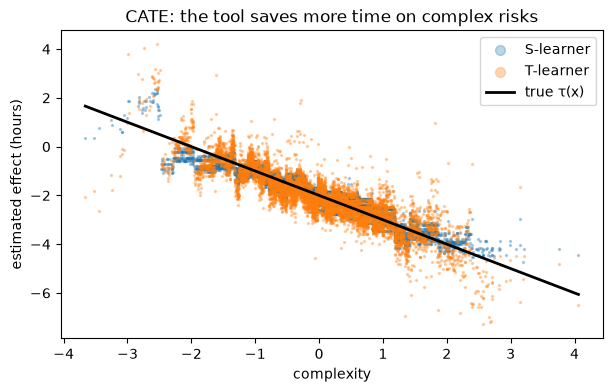

mean abs error, S-learner: 0.242 | T-learner: 0.408


In [9]:
Xdf = df[["complexity", "experience"]]
# S-learner
s_model = GradientBoostingRegressor(random_state=0).fit(Xdf.assign(T=df["T"]), df["Y"])
tau_s = s_model.predict(Xdf.assign(T=1)) - s_model.predict(Xdf.assign(T=0))
# T-learner
m1 = GradientBoostingRegressor(random_state=0).fit(Xdf[df["T"] == 1], df.loc[df["T"] == 1, "Y"])
m0 = GradientBoostingRegressor(random_state=0).fit(Xdf[df["T"] == 0], df.loc[df["T"] == 0, "Y"])
tau_t = m1.predict(Xdf) - m0.predict(Xdf)

order = np.argsort(df["complexity"].values)
plt.figure(figsize=(7, 4))
plt.scatter(df["complexity"], tau_s, s=2, alpha=0.3, label="S-learner")
plt.scatter(df["complexity"], tau_t, s=2, alpha=0.3, label="T-learner")
plt.plot(df["complexity"].values[order], tau[order], "k", lw=2, label="true τ(x)")
plt.xlabel("complexity"); plt.ylabel("estimated effect (hours)"); plt.legend(markerscale=5)
plt.title("CATE: the tool saves more time on complex risks"); plt.show()
print("mean abs error, S-learner:", np.abs(tau_s - tau).mean().round(3), "| T-learner:", np.abs(tau_t - tau).mean().round(3))

**Business reading:** the tool is used mostly on easy risks, but it helps most on complex ones. **Targeting it at complex submissions** would multiply the benefit. That's the kind of insight a Head of AI wants from causal work.

---
## 4.6 Difference-in-Differences (and other quasi-experiments)

### Theory
The tool was rolled out to **Team A** in Q3; **Team B** didn't get it. Comparing A after vs before mixes the tool's effect with everything else that changed over time (market cycle, staff changes). Comparing A vs B mixes it with team differences. **Do both differences:**

$$\boxed{\text{DiD} = (\bar Y_{A,\text{post}} - \bar Y_{A,\text{pre}}) - (\bar Y_{B,\text{post}} - \bar Y_{B,\text{pre}})}$$

**Key assumption, parallel trends:** without the tool, A would have changed by the same amount as B. Check it on several **pre**-periods: the lines should run parallel before the rollout.

As a regression: $Y = \beta_0 + \beta_1 \text{TeamA} + \beta_2 \text{Post} + \boxed{\beta_3}\,(\text{TeamA} \times \text{Post}) + \varepsilon$. Here $\beta_3$ is the DiD estimate.

### Solved Example 4.3
**Q.** Average hours to quote:

| | Pre (Q2) | Post (Q3) |
|---|---|---|
| Team A (got the tool) | 10 | 7 |
| Team B (no tool) | 11 | 10 |

**Solution.** A changed by 7 − 10 = −3. B changed by 10 − 11 = −1 (the general trend: a quieter quarter).
DiD = −3 − (−1) = **−2 hours**.

**Ans.** The tool saved about 2 hours. The before/after comparison alone (−3) would have credited it with the quiet quarter too.

In [10]:
rng = np.random.default_rng(11)
rows = []
for team, base in [("A", 10.0), ("B", 11.0)]:
    for q in range(1, 9):                                  # 8 quarters, rollout after quarter 4
        post = int(q >= 5)
        for _ in range(150):
            y = base - 0.3 * q + (-2.0 if (team == "A" and post) else 0) + rng.normal(0, 2)
            rows.append(dict(team=team, quarter=q, post=post, treated=int(team == "A"), hours=y))
panel = pd.DataFrame(rows)

did = smf.ols("hours ~ treated + post + treated:post", data=panel).fit()
print(did.summary().tables[1])

                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       10.1671      0.083    122.234      0.000      10.004      10.330
treated         -0.8847      0.118     -7.521      0.000      -1.115      -0.654
post            -1.0073      0.118     -8.563      0.000      -1.238      -0.777
treated:post    -2.2014      0.166    -13.233      0.000      -2.528      -1.875


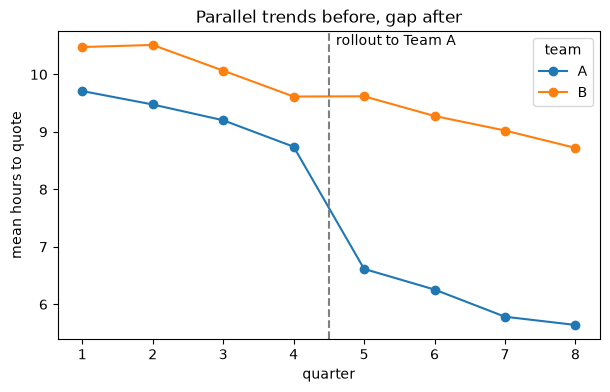

In [11]:
means = panel.groupby(["quarter", "team"])["hours"].mean().unstack()
means.plot(marker="o", figsize=(7, 4))
plt.axvline(4.5, color="grey", ls="--"); plt.text(4.6, means.values.max(), "rollout to Team A")
plt.ylabel("mean hours to quote"); plt.title("Parallel trends before, gap after"); plt.show()

#### Explanation
- `treated:post` is the interaction term, $\beta_3$, which should be close to −2. Read its 95% confidence interval from the table.
- In the plot, both lines slope down together before quarter 5 (parallel trends ✓), then Team A drops by an extra amount.
- **Staggered rollouts** (different teams at different times) need modern estimators such as Callaway–Sant'Anna. Plain two-way fixed effects can be biased there. Mentioning this shows depth.

### Other quasi-experiments (definition level)
| Method | When to use at Aventum | Assumption |
|---|---|---|
| **Regression discontinuity** | The tool auto-routes submissions with a risk score > 0.7. Compare 0.69 with 0.71 | Units just either side of the cut-off are comparable, and nobody games the score |
| **Instrumental variable** | Something that changes tool use but affects $Y$ only through it (e.g. a random IT outage day) | Relevance, and the exclusion restriction (untestable) |
| **Synthetic control** | One unit treated (e.g. one office): build a weighted combo of the other offices that tracks it before treatment | A good pre-period fit |

---
## Exercise 4.1
1. In Solved Example 4.1, which assumption explains why the naive estimate is wrong?
2. A treated unit has $e(x) = 0.25$ and $Y = 8$. What is its contribution to the IPW sum (before dividing by $n$)? What if it were a control?
3. Why does AIPW still work if the propensity model is wrong but the outcome model is right?
4. You want the effect of the AI tool on **bind rate**, and someone suggests controlling for "quote turnaround time". Good idea?
5. DiD: Team A goes 20 → 15, Team B goes 18 → 16. What is the DiD estimate? What must you check before believing it?
6. "Users of the AI tool had 15% better loss ratios." Name two confounders and one collider you'd worry about.

<details><summary><b>Answers</b></summary>

1. **Unconfoundedness is violated in the naive comparison**: complexity drives both tool use and hours. Adjusting for complexity restores it (positivity also holds, since each stratum has both treated and untreated units).
2. Treated: $T Y / e = 8 / 0.25 = 32$. As a control: $-(1-T)Y/(1-e) = -8 / 0.75 = -10.67$.
3. If $\hat\mu$ is right, $E[Y - \hat\mu_1(x) \mid T=1, x] = 0$, so the correction terms average to 0 whatever the weights are. What's left is $\hat\mu_1 - \hat\mu_0$, which is correct.
4. No. Turnaround time is a **mediator** (the tool → a faster quote → more binds). Controlling for it removes part of the effect you want to measure.
5. (15 − 20) − (16 − 18) = −5 − (−2) = **−3**. Check parallel pre-trends over several earlier periods, and that nothing else changed only for Team A at the same time.
6. Confounders: risk quality / line of business (the tool used on better risks), underwriter seniority. Collider: analysing only **bound** policies or **reported** claims, since selection depends on both the tool's recommendation and the risk.
</details>

## Viva / Interview Questions (STRATEGY §9 and §6.2)
**Q. How would you measure the impact of an AI decision tool without an A/B test?**
First I'd draw the DAG with the business: what drives both tool usage and the outcome (risk complexity, line of business, underwriter seniority). If it was rolled out by team or by date, a difference-in-differences with a parallel-trends check. Otherwise adjust for confounders with a doubly robust estimator, check overlap, and run refutation tests (placebo treatment, random common cause, unobserved-confounder sensitivity). I'd also look at heterogeneity: where it helps most. And I'd be upfront that unmeasured confounding can't be ruled out from data, which is why I'd push for a randomised rollout next time.

**Q. What is a doubly robust estimator?**
AIPW: an outcome model's prediction plus an inverse-propensity-weighted correction using its residuals. It's consistent if either the outcome model or the propensity model is right. Double ML generalises this with ML nuisance models and cross-fitting.

## Formula Sheet
| Concept | Formula |
|---|---|
| ATE | $E[Y(1) - Y(0)]$ |
| Adjustment | $\sum_x P(x)(E[Y \mid 1,x] - E[Y \mid 0,x])$ |
| IPW | $\frac1n \sum [TY/e - (1-T)Y/(1-e)]$ |
| AIPW | $\frac1n \sum [\hat\mu_1 - \hat\mu_0 + T(Y - \hat\mu_1)/e - (1-T)(Y - \hat\mu_0)/(1-e)]$ |
| DiD | $(A_{post} - A_{pre}) - (B_{post} - B_{pre})$ |
| Assumptions | unconfoundedness, positivity, SUTVA (+ parallel trends for DiD) |

## How to say it on Friday
> "I haven't applied causal inference to real business data, but I've been working through it this week: potential outcomes, IPW and doubly robust estimators by hand, and DoWhy and EconML on the Lalonde data. What struck me is how far off the naive comparison is when a tool is used selectively, which is exactly what happens when underwriters choose when to use an AI tool. If you've rolled something out team by team, I'd start with a diff-in-diff."